# Chapitre 4 - Exercices 4.7 à 4.12

Ce notebook traite les six derniers exercices du chapitre 4 :

- **4.7** : LSM ou B-tree ? Dimensionner disque et SSD pour une charge donnée
  (calcul) ;
- **4.8** : choisir ses index secondaires et couvrants, mesures à l'appui avec SQLite
  (mini-lab) ;
- **4.9** : intersection de postings lists et recherche floue (calcul et mini-lab) ;
- **4.10** : stockage en colonnes, compression et cube de données (calcul et
  mini-lab) ;
- **4.11** : interprétation, compilation et vectorisation d'une requête (mini-lab) ;
- **4.12** : dimensionner un index vectoriel IVF (calcul, optimisation et mini-lab).

In [1]:
import math
import random
import sqlite3
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import storage as S
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)


def meilleur_temps(f, rep=5):
    best = float("inf")
    for _ in range(rep):
        t0 = time.perf_counter()
        f()
        best = min(best, time.perf_counter() - t0)
    return best

## Exercice 4.7 : LSM ou B-tree ? Dimensionner disque et SSD

**Énoncé.** Un service de télémétrie reçoit 50 000 écritures par seconde
d'enregistrements de 200 octets (clés aléatoires) et sert 20 000 lectures ponctuelles
par seconde. Il dispose d'un SSD de 4 To : 1 Go/s de bande passante d'écriture,
400 000 IOPS de lecture aléatoire, et une endurance de 1 DWPD (on peut écrire 4 To par
jour pendant 5 ans). On compare :

- un **B-tree** (pages de 8 Kio, cache de pages : on estime qu'en moyenne chaque
  écriture fait réécrire un quart de page au point de reprise, plus le WAL) ;
- un **LSM** en leveled, d'amplification d'écriture 12 (WAL compris), avec une lecture
  de bloc par lecture ponctuelle en moyenne (filtres de Bloom) plus 10 % de faux
  positifs et de niveaux non filtrés.

1. Calculer l'amplification d'écriture du B-tree et le débit disque d'écriture des deux
   moteurs. Tiennent-ils sur le SSD ?
2. Calculer la durée de vie du SSD dans chaque cas.
3. Calculer les IOPS de lecture (pages internes du B-tree en cache). Conclure.

**Rappels.** Amplification d'écriture, usure des SSD, lectures prévisibles du B-tree
contre lectures dépendant de la compaction (section *Comparing B-Trees and LSM-Trees* ;
cours 3, section 5).

**Solution.**

*1.* B-tree : par écriture de 200 octets, un quart de page de 8 Kio (2 048 octets) au
point de reprise plus 200 octets de WAL, soit
$\mathrm{WA} = (2\,048 + 200)/200 \approx 11{,}2$. Débit utile :
$5 \times 10^4 \times 200 = 10$ Mo/s. Débit disque : 112 Mo/s pour le B-tree, 120 Mo/s
pour le LSM. Les deux tiennent largement dans 1 Go/s : à ce niveau de charge, c'est
l'**écriture aléatoire** de pages par le B-tree (environ 12 500 pages de 8 Kio par
seconde, soit $5 \times 10^4 / 4$) qui pourrait gêner un disque magnétique, pas un SSD.

*2.* Volume écrit par jour : $112\,\text{Mo/s} \times 86\,400 \approx 9{,}7$ To pour le
B-tree, $10{,}4$ To pour le LSM. L'endurance est de 4 To par jour pendant 5 ans, soit
$7\,300$ To au total : environ $7\,300 / 9{,}7 \approx 750$ jours (2 ans) pour le
B-tree, 700 jours pour le LSM. Les deux **usent le SSD deux fois trop vite**. Leviers :
compresser (le LSM compresse ses blocs bien mieux), réduire l'amplification (size-tiered
pour le LSM, plus grand intervalle de reprise pour le B-tree), ou provisionner plus de
disques. Avec ces hypothèses les deux moteurs sont proches : le livre a raison de dire
qu'il faut mesurer **sa** charge.

*3.* B-tree : une E/S par lecture (la feuille), 20 000 IOPS. LSM : $1{,}1 \times 20\,000
= 22\,000$ IOPS. Les deux restent très loin des 400 000 IOPS du SSD. Mais la compaction
du LSM lit aussi : elle relit environ autant qu'elle écrit, en séquentiel.

In [2]:
utile = 5e4 * 200
wa_bt = (8192 / 4 + 200) / 200
moteurs = pd.DataFrame({"B-tree": [wa_bt, 1.0], "LSM leveled": [12.0, 1.1]},
                       index=["amplification d'écriture", "E/S par lecture"]).T
moteurs["écriture disque (Mo/s)"] = utile * moteurs["amplification d'écriture"] / 1e6
moteurs["To écrits par jour"] = moteurs["écriture disque (Mo/s)"] * 86_400 / 1e6
moteurs["durée de vie du SSD (années)"] = 4 * 365 * 5 / moteurs["To écrits par jour"] / 365
moteurs["IOPS de lecture"] = 2e4 * moteurs["E/S par lecture"]
moteurs["part de la bande passante (%)"] = moteurs["écriture disque (Mo/s)"] / 1000 * 100
moteurs

,amplification d'écriture,E/S par lecture,écriture disque (Mo/s),To écrits par jour,durée de vie du SSD (années),IOPS de lecture,part de la bande passante (%)
B-tree,11.24,1.0,112.4,9.711,2.059,20000.0,11.24
LSM leveled,12.00,1.1,120.0,10.368,1.929,22000.0,12.00


**Vérification graphique** : durée de vie du SSD en fonction de l'amplification
d'écriture, et effet d'une compression des blocs (taux 3) pour le LSM.

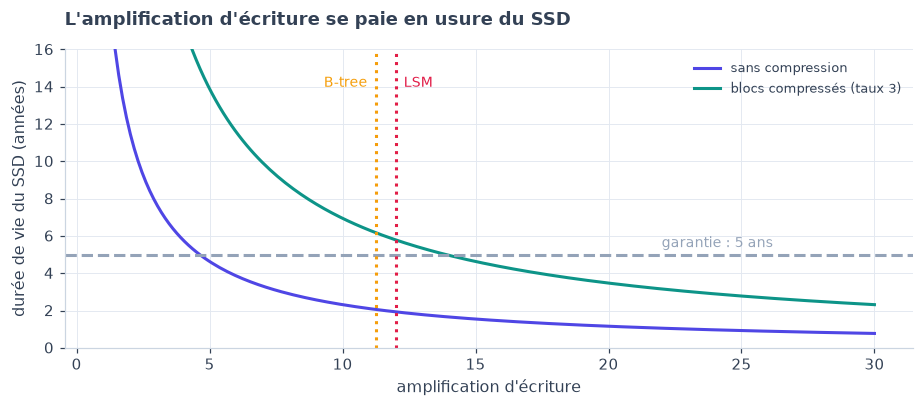

In [3]:
wa = np.linspace(1, 30, 200)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(wa, 7300 / (utile * wa * 86_400 / 1e12) / 365, color=INDIGO, label="sans compression")
ax.plot(wa, 7300 / (utile * wa / 3 * 86_400 / 1e12) / 365, color=TEAL, label="blocs compressés (taux 3)")
ax.axhline(5, color=GRAY, ls="--"); ax.text(22, 5.4, "garantie : 5 ans", color=GRAY, fontsize=9)
for nom, w in [("B-tree", wa_bt), ("LSM", 12)]:
    ax.axvline(w, color=ROSE if nom == "LSM" else AMBER, ls=":")
    if nom == "LSM":
        ax.text(w + 0.3, 14, nom, color=ROSE, fontsize=9)
    else:
        ax.text(w - 0.3, 14, nom, color=AMBER, fontsize=9, ha="right")
ax.set_ylim(0, 16)
ax.set_xlabel("amplification d'écriture"); ax.set_ylabel("durée de vie du SSD (années)")
ax.set_title("L'amplification d'écriture se paie en usure du SSD")
ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

> **À retenir.** Pour dimensionner, on multiplie le débit utile par l'amplification
> d'écriture : on obtient la bande passante consommée et l'usure du SSD. Compression et
> choix de la compaction pèsent autant que la famille de moteur.

## Exercice 4.8 : Choisir ses index secondaires et couvrants (mini-lab SQLite)

**Énoncé.** Une table `commandes(id, client, statut, date, montant, adresse)` de
200 000 lignes reçoit trois requêtes fréquentes :

- **Q1** : les commandes d'un client (`WHERE client = ?`) ;
- **Q2** : le montant total d'un client sur un mois (`SUM(montant) WHERE client = ? AND
  date BETWEEN ? AND ?`) ;
- **Q3** : le nombre de commandes par statut (`WHERE statut = ?`, 5 statuts, dont un
  représente 60 % des lignes).

1. Proposer des index ; prévoir lesquels seront utilisés et pourquoi un index sur
   `statut` est peu utile pour le statut majoritaire.
2. Mesurer avec SQLite le plan et le temps de chaque requête, et le coût des index à
   l'insertion.
3. Conclure sur le compromis lecture / écriture.

**Rappels.** Index secondaires, index concaténé (préfixe), index couvrant, sélectivité
(sections *Multicolumn and Secondary Indexes* et
*Storing Values Within the Index* ; cours 4,
sections 1 à 3).

**Solution (prévisions).** Un index concaténé `(client, date)` sert Q1 (préfixe
`client`) et Q2 (préfixe complet, intervalle sur `date`) ; en y incluant `montant`
(`(client, date, montant)`), il **couvre** Q2. Pour Q3, un index sur `statut` aide les
statuts rares ; pour le statut majoritaire (60 % des lignes), parcourir l'index puis la
table coûterait plus qu'un parcours complet. Mais pour un simple `COUNT(*)`, l'index sur
`statut` couvre la requête : SQLite peut compter dans l'index, plus petit que la table.

In [4]:
rng = np.random.default_rng(0)
N = 200_000
rows = list(zip(range(N), S.zipf_keys(N, 20_000, s=0.7, seed=1).tolist(),
                rng.choice(["livrée", "expédiée", "payée", "annulée", "litige"], N, p=[0.6, 0.2, 0.15, 0.04, 0.01]),
                rng.integers(0, 365, N).tolist(), np.round(rng.lognormal(3, 0.7, N), 2).tolist(), ["x" * 120] * N))
REQ = {"Q1": "SELECT id, montant FROM commandes WHERE client = 77",
       "Q2": "SELECT SUM(montant) FROM commandes WHERE client = 77 AND date BETWEEN 100 AND 130",
       "Q3 (litige)": "SELECT COUNT(*) FROM commandes WHERE statut = 'litige'",
       "Q3 (livrée)": "SELECT COUNT(*) FROM commandes WHERE statut = 'livrée'"}
CONFIGS = {"aucun index": [],
           "(client)": ["CREATE INDEX i1 ON commandes(client)"],
           "(client, date)": ["CREATE INDEX i2 ON commandes(client, date)"],
           "(client, date, montant) + (statut)": ["CREATE INDEX i3 ON commandes(client, date, montant)",
                                                   "CREATE INDEX i4 ON commandes(statut)"]}
resultats, plans, insertion = [], {}, {}
for nom, ddl in CONFIGS.items():
    con = sqlite3.connect(":memory:")
    con.execute("CREATE TABLE commandes (id INTEGER PRIMARY KEY, client INT, statut TEXT, date INT, "
                "montant REAL, adresse TEXT)")
    for d in ddl:
        con.execute(d)
    t0 = time.perf_counter()
    con.executemany("INSERT INTO commandes VALUES (?, ?, ?, ?, ?, ?)", rows)
    con.commit()
    insertion[nom] = (time.perf_counter() - t0) / N * 1e6
    for q, sql in REQ.items():
        plan = " | ".join(r[-1] for r in con.execute("EXPLAIN QUERY PLAN " + sql))
        resultats.append(dict(configuration=nom, requete=q,
                              us=meilleur_temps(lambda: con.execute(sql).fetchall(), 5) * 1e6, plan=plan))
    con.close()
res = pd.DataFrame(resultats)
res.pivot(index="requete", columns="configuration", values="us")[list(CONFIGS)].round(0)

configuration,aucun index,(client),"(client, date)","(client, date, montant) + (statut)"
requete,,,,
Q1,3834.0,2.0,2.0,2.0
Q2,3623.0,1.0,1.0,1.0
Q3 (litige),5003.0,5924.0,5356.0,30.0
Q3 (livrée),5598.0,5951.0,5764.0,1845.0


In [5]:
res[res.configuration == "(client, date, montant) + (statut)"][["requete", "plan"]]

,requete,plan
12,Q1,SEARCH commandes USING COVERING INDEX i3 (clie...
13,Q2,SEARCH commandes USING COVERING INDEX i3 (clie...
14,Q3 (litige),SEARCH commandes USING COVERING INDEX i4 (stat...
15,Q3 (livrée),SEARCH commandes USING COVERING INDEX i4 (stat...


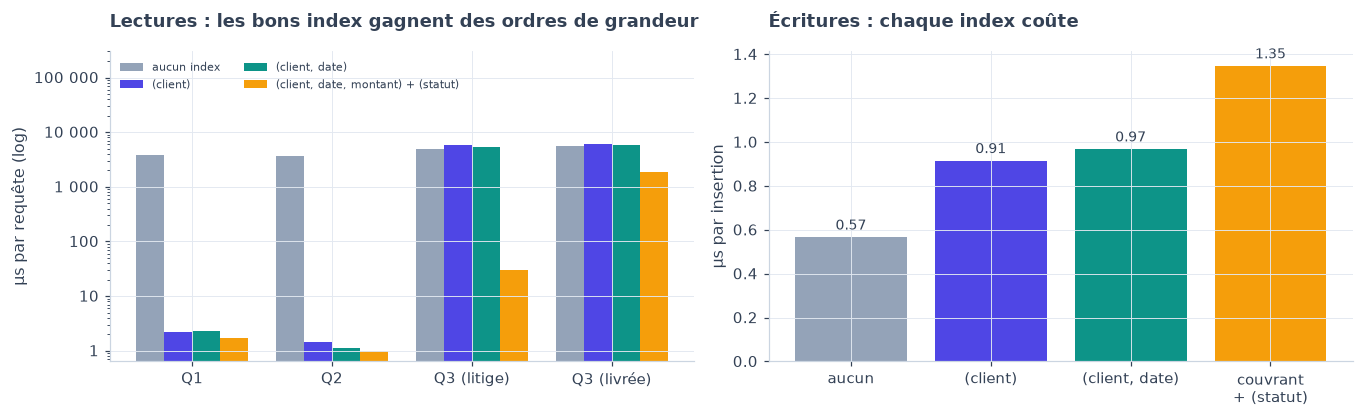

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9))
piv = res.pivot(index="requete", columns="configuration", values="us")[list(CONFIGS)]
x = np.arange(len(piv))
for j, (nom, c) in enumerate(zip(CONFIGS, [GRAY, INDIGO, TEAL, AMBER])):
    axes[0].bar(x + (j - 1.5) * 0.2, piv[nom], 0.2, color=c, label=nom)
axes[0].set_yscale("log"); S.plain_log_ticks(axes[0])
axes[0].set_xticks(x, piv.index); axes[0].set_ylabel("µs par requête (log)")
axes[0].set_title("Lectures : les bons index gagnent des ordres de grandeur")
axes[0].set_ylim(top=3e5)
axes[0].legend(fontsize=7.5, ncol=2, loc="upper left")
ins = pd.Series(insertion)
axes[1].bar(range(len(ins)), ins.values, color=[GRAY, INDIGO, TEAL, AMBER])
axes[1].set_xticks(range(len(ins)), ["aucun", "(client)", "(client, date)", "couvrant\n+ (statut)"])
annotate_bars(axes[1], "{:.2f}")
axes[1].set_ylabel("µs par insertion"); axes[1].set_title("Écritures : chaque index coûte")
finish(fig)
plt.show()

**Lecture des résultats.** Q1 et Q2 passent d'un parcours complet (`SCAN`) à une
recherche dans l'index (`SEARCH ... USING INDEX`), et Q2 devient `USING COVERING INDEX`
avec l'index `(client, date, montant)` : la table n'est plus lue. Pour Q3, l'index sur
`statut` couvre le `COUNT(*)` : le statut rare est quasi instantané, le statut
majoritaire reste coûteux (il faut compter 120 000 entrées), mais moins qu'un parcours de
la table. Côté écriture, chaque index ajouté alourdit l'insertion : c'est le compromis
du livre, qu'on arbitre d'après la fréquence des requêtes.

> **À retenir.** Un index concaténé sert tous les préfixes de ses colonnes ; y ajouter
> les colonnes lues le rend couvrant. Un index sur une colonne peu sélective aide peu,
> sauf s'il couvre la requête. Et chaque index se paie à l'écriture.

## Exercice 4.9 : Intersection de postings lists et recherche floue

**Énoncé.**

1. Deux postings lists triées ont $m$ et $n$ éléments ($m \ll n$). Comparer le coût de
   l'intersection par **fusion** ($O(m + n)$) et par **recherche dichotomique** de chaque
   élément de la petite liste dans la grande ($O(m \log n)$). À partir de quel rapport
   $n/m$ la dichotomie gagne-t-elle ? Vérifier en comptant les comparaisons.
2. Pour corriger une faute de frappe dans un mot de longueur $L$ sur un alphabet de $A$
   lettres, combien de chaînes sont à distance d'édition 1 (en comptant les doublons) ?
   Application : $L = 8$, $A = 26$. Pourquoi est-il plus efficace de parcourir un trie du
   vocabulaire que de générer ces chaînes et de les chercher une à une ?

**Rappels.** Index inversé, postings lists, distance d'édition, trie et automate de
Levenshtein (section *Full-Text Search* ;
cours 4, section 4).

**Solution.**

*1.* La fusion fait au plus $m + n$ comparaisons ; la dichotomie environ
$m \lceil \log_2 (n+1) \rceil$. La dichotomie gagne dès que $m \log_2 n < m + n$, soit
environ $n/m > \log_2 n$ : pour $n = 10^6$, dès que la grande liste est une vingtaine de
fois plus longue que la petite. Les moteurs réels combinent les deux (recherche
exponentielle, *galloping*, ou listes à sauts).

*2.* Suppressions : $L$ ; substitutions : $L(A - 1)$ ; insertions : $(L + 1)A$. Total
$L + L(A-1) + (L+1)A = 2LA + A$ ; pour $L = 8$, $A = 26$ : $16 \times 26 + 26 = 442$
chaînes, dont l'immense majorité ne sont pas des mots. Les chercher une à une coûte 442
recherches ; et à distance 2, il y en aurait environ $442^2 / 2 \approx 10^5$. Le trie
partage les préfixes : une branche est abandonnée dès que toute la ligne de la table de
Levenshtein dépasse la distance permise, si bien qu'on n'examine que des préfixes de
vrais mots.

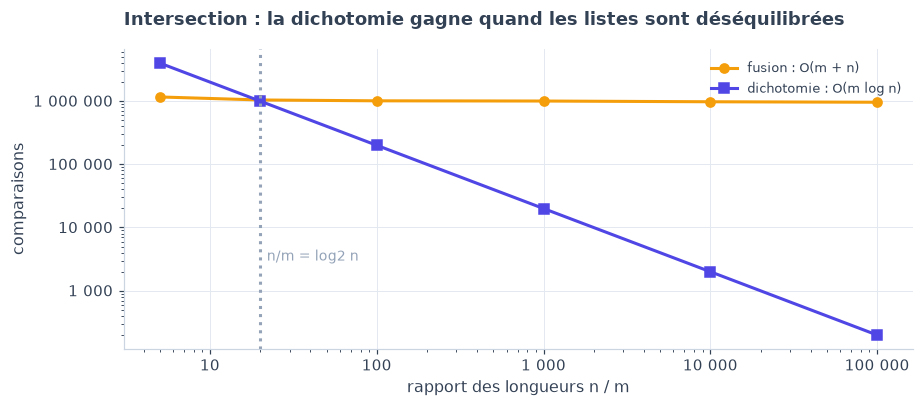

,m,rapport_n_sur_m,fusion,dichotomie
0,10,100000.0,957441,199
1,100,10000.0,974152,1997
2,1000,1000.0,1000409,19953
3,10000,100.0,1008028,199509
4,50000,20.0,1039813,997625
5,200000,5.0,1160047,3990450


In [7]:
def intersect_fusion(a, b):
    i = j = comps = 0
    out = []
    while i < len(a) and j < len(b):
        comps += 1
        if a[i] == b[j]:
            out.append(a[i]); i += 1; j += 1
        elif a[i] < b[j]:
            i += 1
        else:
            j += 1
    return out, comps


def intersect_dicho(petite, grande):
    comps, out = 0, []
    for x in petite:
        lo, hi = 0, len(grande)
        while lo < hi:
            comps += 1
            mid = (lo + hi) // 2
            if grande[mid] < x:
                lo = mid + 1
            else:
                hi = mid
        if lo < len(grande) and grande[lo] == x:
            out.append(x)
    return out, comps


rng = np.random.default_rng(3)
n = 1_000_000
grande = np.sort(rng.choice(5_000_000, n, replace=False)).tolist()
rows = []
for m in [10, 100, 1_000, 10_000, 50_000, 200_000]:
    petite = sorted(rng.choice(5_000_000, m, replace=False).tolist())
    r1, c1 = intersect_fusion(petite, grande)
    r2, c2 = intersect_dicho(petite, grande)
    assert r1 == r2
    rows.append(dict(m=m, rapport_n_sur_m=n / m, fusion=c1, dichotomie=c2))
inter = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.loglog(inter.rapport_n_sur_m, inter.fusion, "o-", color=AMBER, label="fusion : O(m + n)")
ax.loglog(inter.rapport_n_sur_m, inter.dichotomie, "s-", color=INDIGO, label="dichotomie : O(m log n)")
ax.axvline(math.log2(n), color=GRAY, ls=":"); ax.text(math.log2(n) * 1.1, 3e3, "n/m = log2 n", color=GRAY, fontsize=9)
S.plain_log_ticks(ax, "both")
ax.set_xlabel("rapport des longueurs n / m"); ax.set_ylabel("comparaisons")
ax.set_title("Intersection : la dichotomie gagne quand les listes sont déséquilibrées")
ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()
inter

In [8]:
L_, A_ = 8, 26
print("chaînes à distance 1 :", L_ + L_ * (A_ - 1) + (L_ + 1) * A_)
alphabet = "abcdefghijklmnopqrstuvwxyz"
vocab = S.make_vocabulary(20_000, seed=4)
trie = S.Trie(vocab)
ens = set(vocab)


def voisins_1(w):
    out = set()
    for i in range(len(w) + 1):
        for ch in alphabet:
            out.add(w[:i] + ch + w[i:])
        if i < len(w):
            out.add(w[:i] + w[i + 1:])
            for ch in alphabet:
                out.add(w[:i] + ch + w[i + 1:])
    out.discard(w)
    return out


rows = []
for w in random.Random(1).sample(vocab, 20):
    faute = w[:2] + "q" + w[3:]
    gen = voisins_1(faute)
    trouves_gen = sorted(x for x in gen | {faute} if x in ens and S.levenshtein(x, faute) <= 1)
    res_trie, visites = trie.fuzzy(faute, 1)
    assert sorted(r for r, _ in res_trie) == trouves_gen
    rows.append(dict(mot=w, requete=faute, chaines_generees=len(gen), noeuds_du_trie_visites=visites,
                     resultats=len(trouves_gen)))
pd.DataFrame(rows).head(6)

chaînes à distance 1 : 442


,mot,requete,chaines_generees,noeuds_du_trie_visites,resultats
0,camipo,caqipo,332,433,2
1,detionse,deqionse,434,425,1
2,vimo,viqo,230,403,9
3,voonli,voqnli,332,355,1
4,vadiladi,vaqiladi,434,448,1
5,beentdi,beqntdi,383,380,1


Les deux méthodes trouvent exactement les mêmes mots (vérifié par `assert`). La
génération produit plusieurs centaines de chaînes (moins que $2LA + A$ car les doublons
sont éliminés), à chercher une à une ; le trie visite un nombre de nœuds du même ordre,
mais en un seul parcours qui partage les préfixes, et l'écart se creuse énormément à
distance 2.

> **À retenir.** Pour intersecter des listes déséquilibrées, chercher les éléments de la
> petite dans la grande ($m \log n$) bat la fusion ($m + n$). Pour la recherche floue, on
> parcourt le vocabulaire (trie, automate) au lieu de générer toutes les variantes.

## Exercice 4.10 : Stockage en colonnes, compression et cube de données

**Énoncé.** Une table de faits contient $10^{10}$ ventes ; 100 colonnes de 8 octets en
stockage par lignes. La requête type lit 4 colonnes : `date_key` (3 650 valeurs
distinctes), `product_sk` (100 000), `store_sk` (1 000) et `quantity`.

1. Combien d'octets lit un parcours complet en lignes ? En colonnes non compressées ?
2. Avec un codage par dictionnaire, combien de bits par valeur pour chacune des trois
   colonnes de dimension ? Taille totale des 4 colonnes (quantité sur 8 bits) ?
3. Si la table est triée par `date_key`, combien de plages pour cette colonne ? Combien
   d'octets avec un RLE (valeur + longueur sur 8 octets) ?
4. Un cube complet sur (date, produit, magasin) aurait combien de cellules ? Est-ce
   raisonnable ? Combien d'agrégats dans le treillis ? Vérifier sur `S.make_sales` le
   nombre de cellules **non vides** de chaque agrégat.

**Rappels.** Stockage en colonnes, compression par dictionnaire et RLE, ordre de tri,
cubes de données (section *Column-Oriented Storage* et section
*Materialized Views and Data Cubes* ;
cours 5).

**Solution.**

*1.* En lignes : $10^{10} \times 100 \times 8 = 8 \times 10^{12}$ octets, soit 8 To ;
en colonnes : $10^{10} \times 4 \times 8 = 320$ Go. Un facteur 25 rien qu'en ne lisant
que les colonnes utiles.

*2.* $\lceil \log_2 3\,650 \rceil = 12$ bits, $\lceil \log_2 10^5 \rceil = 17$ bits,
$\lceil \log_2 1\,000 \rceil = 10$ bits, plus 8 bits de quantité : 47 bits par ligne,
soit $10^{10} \times 47 / 8 \approx 59$ Go. Encore un facteur 5,4.

*3.* Triée par date : 3 650 plages, soit $3\,650 \times 16 \approx 58$ Ko pour une
colonne de $10^{10}$ valeurs. La colonne `date_key` devient gratuite.

*4.* $3\,650 \times 10^5 \times 1\,000 = 3{,}65 \times 10^{11}$ cellules, de l'ordre de
la taille de la table elle-même : un cube dense sur ces dimensions n'a pas de sens (il
serait surtout vide). Le treillis contient $2^3 = 8$ agrégats ; on matérialise plutôt
les agrégats les plus petits et les plus utiles (par exemple (date, magasin) : 3,65
millions de cellules).

In [9]:
N_, cols = 1e10, 100
calc = pd.Series({
    "parcours en lignes (Go)": N_ * cols * 8 / 1e9,
    "4 colonnes non compressées (Go)": N_ * 4 * 8 / 1e9,
    "4 colonnes, dictionnaire (Go)": N_ * (S.bits_for(3650) + S.bits_for(10**5) + S.bits_for(1000) + 8) / 8 / 1e9,
    "date_key triée en RLE (Ko)": 3650 * 16 / 1e3,
    "cellules du cube dense (milliards)": 3650 * 1e5 * 1000 / 1e9,
}).round(2).to_frame("valeur")
calc

,valeur
parcours en lignes (Go),8000.00
4 colonnes non compressées (Go),320.00
"4 colonnes, dictionnaire (Go)",58.75
date_key triée en RLE (Ko),58.40
cellules du cube dense (milliards),365.00


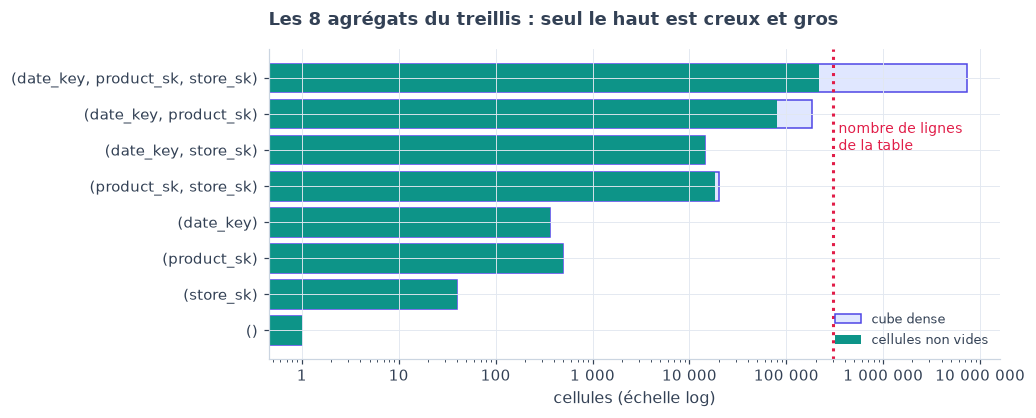

,agregat,cellules_non_vides,cellules_denses,remplissage
0,"(date_key, product_sk, store_sk)",218388,7300000,0.030
1,"(date_key, product_sk)",80339,182500,0.440
2,"(date_key, store_sk)",14600,14600,1.000
3,"(product_sk, store_sk)",18297,20000,0.915
4,(date_key),365,365,1.000
5,(product_sk),500,500,1.000
6,(store_sk),40,40,1.000
7,(),1,1,1.000


In [10]:
fact, *_ = S.make_sales(300_000, n_extra_cols=0, seed=2)
cube = S.data_cube(fact, ["date_key", "product_sk", "store_sk"], "quantity")
rows = []
dims_taille = {"date_key": fact.date_key.nunique(), "product_sk": fact.product_sk.nunique(),
               "store_sk": fact.store_sk.nunique()}
for cle, vue in cube.items():
    dense = int(np.prod([dims_taille[d] for d in cle])) if cle else 1
    rows.append(dict(agregat="(" + ", ".join(cle) + ")", cellules_non_vides=1 if not cle else len(vue),
                     cellules_denses=dense))
tre = pd.DataFrame(rows)
tre["remplissage"] = tre.cellules_non_vides / tre.cellules_denses
fig, ax = plt.subplots(figsize=(9.5, 3.9))
ax.barh(range(len(tre)), tre.cellules_denses, color=LIGHT[INDIGO], edgecolor=INDIGO, label="cube dense")
ax.barh(range(len(tre)), tre.cellules_non_vides, color=TEAL, label="cellules non vides")
ax.set_yticks(range(len(tre)), tre.agregat); ax.invert_yaxis()
ax.set_xscale("log"); S.plain_log_ticks(ax, "x")
ax.axvline(len(fact), color=ROSE, ls=":"); ax.text(len(fact) * 1.15, 2.0, "nombre de lignes\nde la table", color=ROSE, fontsize=9)
ax.set_xlabel("cellules (échelle log)"); ax.set_title("Les 8 agrégats du treillis : seul le haut est creux et gros")
ax.legend(fontsize=8.5, loc="lower right")
plt.tight_layout(); plt.show()
tre

Sur 300 000 ventes, le cube complet (date, produit, magasin) aurait 7,3 millions de
cellules dont moins de 5 % sont non vides : il ne réduit presque rien par rapport à la
table. Les agrégats plus bas dans le treillis, (date, magasin) ou (produit), sont
petits et denses : ce sont eux qu'on matérialise.

> **À retenir.** Ne lire que les colonnes utiles, puis les compresser (dictionnaire,
> RLE sur colonne triée) divise les octets lus par des facteurs multiplicatifs. Un cube
> dense sur des dimensions de grande cardinalité explose : on matérialise les agrégats
> petits et fréquemment demandés.

## Exercice 4.11 : Interprétation, compilation et vectorisation (mini-lab)

**Énoncé.** On modélise le temps d'exécution d'un filtre à $k$ prédicats sur $n$ lignes
par $t = n\,(a + b\,k)$ : $a$ est le coût fixe par ligne (boucle, accès à la colonne
cible), $b$ le coût par prédicat évalué.

1. Mesurer $t$ pour $k = 1$ à 5 prédicats (tous vrais, pour qu'ils soient tous évalués)
   avec l'interpréteur `S.interpret_query`, le code généré `S.compile_query` et une
   version vectorisée numpy, sur 100 000 lignes.
2. Estimer $a$ et $b$ par régression linéaire pour chaque approche. Quelle part du
   surcoût de l'interpréteur la compilation supprime-t-elle ?
3. Expliquer pourquoi la version vectorisée a un coût par prédicat si faible.

**Rappels.** Interprétation, compilation de requêtes, traitement vectorisé (section
*Query Execution: Compilation and Vectorization* ; cours 5, sections 4 et 8).

**Solution (mesures).**

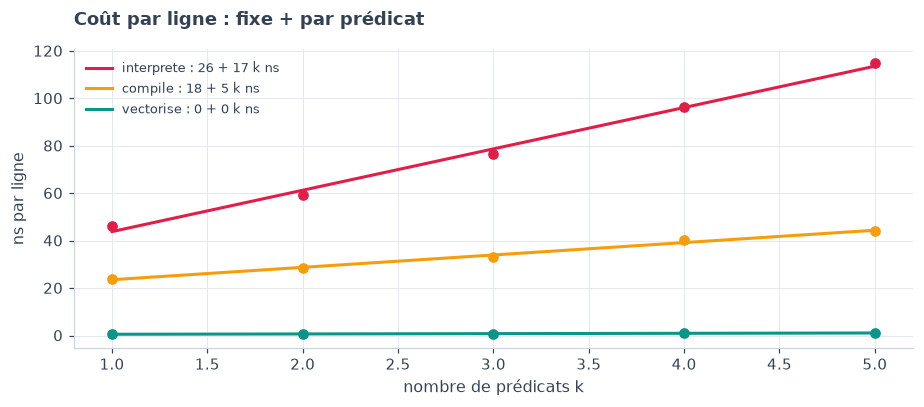

,a_ns_par_ligne,b_ns_par_predicat
interprete,26.424,17.438
compile,18.344,5.218
vectorise,0.426,0.134


In [11]:
n = 100_000
rng = np.random.default_rng(0)
cols_np = {f"c{j}": rng.integers(0, 10, n) for j in range(5)}
cols_np["qty"] = rng.integers(1, 5, n)
cols_py = {c: v.tolist() for c, v in cols_np.items()}
rows = []
for k in range(1, 6):
    where = [(f"c{j}", ">=", 0) for j in range(k)]  # toujours vrai : tous les prédicats sont évalués
    fn, _ = S.compile_query(where, "qty")

    def vect():
        m = np.ones(n, dtype=bool)
        for c, _, v in where:
            m &= cols_np[c] >= v
        return int(cols_np["qty"][m].sum())

    assert S.interpret_query(cols_py, where, "qty") == fn(cols_py) == vect()
    rows.append(dict(k=k, interprete=meilleur_temps(lambda: S.interpret_query(cols_py, where, "qty"), 3),
                     compile=meilleur_temps(lambda: fn(cols_py), 3), vectorise=meilleur_temps(vect, 3)))
mes = pd.DataFrame(rows)
coefs = {}
for col in ["interprete", "compile", "vectorise"]:
    b_, a_ = np.polyfit(mes.k, mes[col] / n * 1e9, 1)
    coefs[col] = dict(a_ns_par_ligne=a_, b_ns_par_predicat=b_)
coefs = pd.DataFrame(coefs).T
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for col, c in zip(["interprete", "compile", "vectorise"], [ROSE, AMBER, TEAL]):
    ax.plot(mes.k, mes[col] / n * 1e9, "o", color=c)
    ax.plot(mes.k, coefs.loc[col, "a_ns_par_ligne"] + coefs.loc[col, "b_ns_par_predicat"] * mes.k, "-", color=c,
            label=f"{col} : {coefs.loc[col, 'a_ns_par_ligne']:.0f} + {coefs.loc[col, 'b_ns_par_predicat']:.0f} k ns")
ax.set_xlabel("nombre de prédicats k"); ax.set_ylabel("ns par ligne")
ax.set_title("Coût par ligne : fixe + par prédicat")
ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()
coefs

*2.* L'interpréteur paie, pour chaque ligne et chaque prédicat, la traversée du plan et
un appel de fonction (`operator.ge`) ; le code généré écrit la comparaison en dur dans
la boucle : le coût par prédicat baisse fortement, et le coût fixe aussi (pas de
boucle sur le plan). Le rapport des pentes donne la part du surcoût d'interprétation
supprimée par la compilation : ici, le coût par prédicat passe d'environ 18 à 6 ns,
soit les deux tiers en moins (et le coût fixe par ligne baisse aussi d'un tiers).

*3.* La version vectorisée paie le surcoût de l'interpréteur Python **une fois par
colonne**, pas une fois par valeur : chaque prédicat est une boucle native sur 100 000
valeurs contiguës (avec SIMD), d'où quelques nanosecondes par ligne et par prédicat.
C'est exactement l'argument du livre : les deux approches éliminent le surcoût par
valeur, l'une en générant du code, l'autre en traitant des lots.

> **À retenir.** Le coût d'une requête analytique se décompose en coût fixe par ligne et
> coût par prédicat ; compilation et vectorisation attaquent tous deux le surcoût
> d'interprétation par valeur.

## Exercice 4.12 : Dimensionner un index vectoriel IVF

**Énoncé.** On indexe $n = 10^8$ documents par des embeddings de dimension 768.

1. Quelle mémoire pour les vecteurs en `float32` ? Avec une quantification qui ramène
   chaque vecteur à 64 octets ?
2. Un index IVF a `nlist` listes et chaque requête sonde `nprobe` listes. Exprimer le
   nombre de distances calculées par requête, et montrer qu'il est minimal pour
   $\text{nlist}^* = \sqrt{\text{nprobe} \cdot n}$. Application : nprobe = 16.
3. Quel gain par rapport à l'index plat ?
4. Mini-lab : sur 20 000 vecteurs synthétiques, mesurer rappel@10 et coût pour
   plusieurs `nlist` à nprobe fixé, et comparer au modèle.

**Rappels.** Index plat, IVF, sondes, rappel (section *Vector Embeddings* ; cours 6,
sections 3 et 4).

**Solution.**

*1.* $10^8 \times 768 \times 4 = 307$ Go en `float32` ; $10^8 \times 64 = 6{,}4$ Go
quantifiés (au prix d'une perte de précision des distances).

*2.* On compare la requête aux nlist centroïdes, puis aux vecteurs des nprobe listes
sondées, de taille moyenne $n/\text{nlist}$ :
$$C(\text{nlist}) = \text{nlist} + \text{nprobe}\,\frac{n}{\text{nlist}}.$$
$C'(\text{nlist}) = 1 - \text{nprobe}\,n/\text{nlist}^2 = 0$ donne
$\text{nlist}^* = \sqrt{\text{nprobe}\,n}$ et $C^* = 2\sqrt{\text{nprobe}\,n}$. Pour
nprobe = 16 : $\text{nlist}^* = 40\,000$ et $C^* = 80\,000$ distances.

*3.* Contre $10^8$ pour l'index plat : un gain de 1 250. En pratique, les listes ont
des tailles inégales (les thèmes populaires forment de grosses listes), ce qui dégrade un
peu ce chiffre.

mémoire float32 : 307 Go ; quantifiée : 6.4 Go ; nlist* = 40 000 ; C* = 80 000 distances


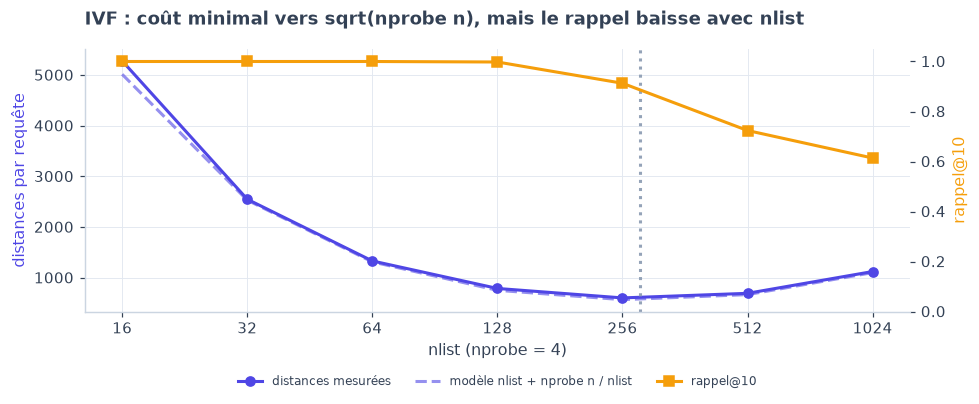

,nlist,rappel,distances_mesurees,distances_modele
0,16,1.000,5279.97,5016.000
1,32,1.000,2550.13,2532.000
2,64,1.000,1332.66,1314.000
3,128,0.998,789.60,753.000
4,256,0.913,602.85,568.500
5,512,0.724,693.53,668.250
6,1024,0.614,1123.37,1102.125


In [12]:
from ddia import storage_vectors as V

n_v, nprobe = 1e8, 16
print(f"mémoire float32 : {n_v * 768 * 4 / 1e9:.0f} Go ; quantifiée : {n_v * 64 / 1e9:.1f} Go ;",
      f"nlist* = {math.sqrt(nprobe * n_v):,.0f} ; C* = {2 * math.sqrt(nprobe * n_v):,.0f} distances".replace(",", " "))
X, _ = V.make_embeddings(20_000, dim=32, n_topics=40, seed=7)
Q = V.make_queries(X, 100, seed=8)
flat = V.FlatIndex(X)
verite = [flat.search(q, 10) for q in Q]
rows = []
for nlist in [16, 32, 64, 128, 256, 512, 1024]:
    ivf = V.IVFIndex(X, nlist=nlist, seed=0)
    ivf.distance_computations = 0
    rec = np.mean([V.recall_at_k(ivf.search(q, 10, nprobe=4), t) for q, t in zip(Q, verite)])
    rows.append(dict(nlist=nlist, rappel=rec, distances_mesurees=ivf.distance_computations / len(Q),
                     distances_modele=nlist + 4 * len(X) / nlist))
ivf_tab = pd.DataFrame(rows)
fig, ax1 = plt.subplots(figsize=(9, 3.9))
ax1.plot(ivf_tab.nlist, ivf_tab.distances_mesurees, "o-", color=INDIGO, label="distances mesurées")
ax1.plot(ivf_tab.nlist, ivf_tab.distances_modele, "--", color=INDIGO, alpha=0.6, label="modèle nlist + nprobe n / nlist")
ax1.axvline(math.sqrt(4 * len(X)), color=GRAY, ls=":")
ax1.set_xscale("log", base=2); ax1.set_xticks(ivf_tab.nlist, ivf_tab.nlist.astype(str)); ax1.minorticks_off()
ax1.set_xlabel("nlist (nprobe = 4)"); ax1.set_ylabel("distances par requête", color=INDIGO)
ax2 = ax1.twinx()
ax2.plot(ivf_tab.nlist, ivf_tab.rappel, "s-", color=AMBER, label="rappel@10")
ax2.set_ylabel("rappel@10", color=AMBER); ax2.set_ylim(0, 1.05); ax2.grid(False)
ax1.set_title("IVF : coût minimal vers sqrt(nprobe n), mais le rappel baisse avec nlist")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
plt.tight_layout(); plt.show()
ivf_tab

Le coût mesuré suit le modèle et passe par un minimum vers
$\sqrt{4 \times 20\,000} \approx 283$ listes. Mais à nprobe fixé, le **rappel baisse**
quand nlist augmente : des listes plus petites rendent plus probable qu'un vrai voisin
tombe dans une liste non sondée. Le vrai réglage est donc conjoint : on choisit nlist
autour de $\sqrt{n}$ à quelques $\sqrt{n}$, puis on augmente nprobe jusqu'au rappel
voulu.

> **À retenir.** Un IVF coûte $\text{nlist} + \text{nprobe}\,n/\text{nlist}$ distances
> par requête, minimal pour $\text{nlist} \approx \sqrt{\text{nprobe}\,n}$ ; le rappel
> impose ensuite le nombre de sondes. La mémoire des vecteurs (souvent des centaines de
> Go) pousse à les quantifier.